In [2]:
# ==========================================
# CELL 2: IMPORT LIBRARIES
# ==========================================

import torch
import torch.nn as nn
import torch.optim as optim

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import time
import random

from collections import Counter

from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from torch.utils.data import Dataset, DataLoader

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# ==========================================
# CELL 3: CHECK GPU
# ==========================================

print("PyTorch version:", torch.__version__)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [4]:
# ==========================================
# CELL 4: RANDOM SEEDS
# ==========================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [5]:
# ==========================================
# CELL 5: LOAD AG NEWS
# ==========================================

dataset = load_dataset("fancyzhx/ag_news")

print(dataset)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [6]:
# ==========================================
# CELL 6: INSPECT DATASET
# ==========================================

print("First article:")
print(dataset["train"][0])

print("\nDataset features:")
print(dataset["train"].features)

First article:
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}

Dataset features:
{'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}


In [7]:
# ==========================================
# CELL 7: CONVERT TO DATAFRAME
# ==========================================

original_train_df = pd.DataFrame(
    dataset["train"]
)

original_test_df = pd.DataFrame(
    dataset["test"]
)

print("Original training samples:",
      len(original_train_df))

print("Original test samples:",
      len(original_test_df))

Original training samples: 120000
Original test samples: 7600


In [8]:
# ==========================================
# CELL 8: CREATE BALANCED 20K DATASET
# ==========================================

SAMPLES_PER_CLASS = 5000

df_20k = (
    original_train_df
    .groupby("label", group_keys=False)
    .sample(
        n=SAMPLES_PER_CLASS,
        random_state=SEED
    )
    .reset_index(drop=True)
)

print("Total samples:", len(df_20k))

print("\nClass distribution:")
print(
    df_20k["label"]
    .value_counts()
    .sort_index()
)

Total samples: 20000

Class distribution:
label
0    5000
1    5000
2    5000
3    5000
Name: count, dtype: int64


In [9]:
# ==========================================
# CELL 9: SHUFFLE 20K DATASET
# ==========================================

df_20k = (
    df_20k
    .sample(
        frac=1,
        random_state=SEED
    )
    .reset_index(drop=True)
)

print("First 30 labels after shuffling:")
print(
    df_20k["label"]
    .head(30)
    .tolist()
)

First 30 labels after shuffling:
[2, 0, 1, 0, 2, 2, 2, 0, 3, 1, 0, 1, 3, 3, 2, 1, 3, 3, 1, 0, 1, 1, 3, 3, 1, 3, 3, 2, 3, 0]


In [10]:
# ==========================================
# CELL 10: CATEGORY NAMES
# ==========================================

label_names = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

df_20k["category"] = (
    df_20k["label"]
    .map(label_names)
)

print(
    df_20k[
        ["text", "label", "category"]
    ].head()
)

                                                text  label  category
0  Wal-Mart Launches Rare Newspaper Ad Blitz (Reu...      2  Business
1  Hirst restaurant sale makes 11m Fixtures and f...      0     World
2  Miami Heat Team Report - November 10 (Sports N...      1    Sports
3  Ukrainian Government Blamed for Poisoning Oppo...      0     World
4  Treasuries Rise on Greenspan's Remarks  NEW YO...      2  Business


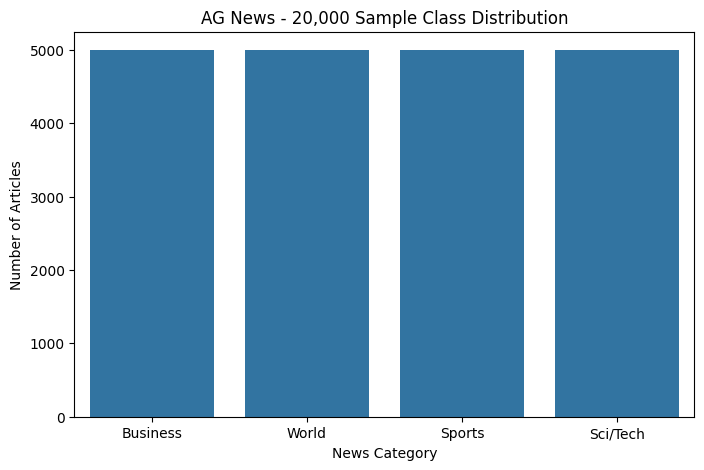

In [11]:
# ==========================================
# CELL 11: CLASS DISTRIBUTION
# ==========================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_20k,
    x="category"
)

plt.title(
    "AG News - 20,000 Sample Class Distribution"
)

plt.xlabel("News Category")
plt.ylabel("Number of Articles")

plt.show()

In [12]:
# ==========================================
# CELL 12: SAVE DATASET
# ==========================================

df_20k.to_csv(
    "ag_news_20k.csv",
    index=False
)

print("Saved as ag_news_20k.csv")

Saved as ag_news_20k.csv


In [13]:
# ==========================================
# CELL 13: TRAIN/VALIDATION SPLIT
# ==========================================

train_df, val_df = train_test_split(
    df_20k,
    test_size=0.20,
    random_state=SEED,
    stratify=df_20k["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

Training samples: 16000
Validation samples: 4000


In [14]:
# ==========================================
# CELL 14: CHECK SPLIT DISTRIBUTION
# ==========================================

print("Training distribution:")
print(
    train_df["label"]
    .value_counts()
    .sort_index()
)

print("\nValidation distribution:")
print(
    val_df["label"]
    .value_counts()
    .sort_index()
)

Training distribution:
label
0    4000
1    4000
2    4000
3    4000
Name: count, dtype: int64

Validation distribution:
label
0    1000
1    1000
2    1000
3    1000
Name: count, dtype: int64


In [15]:
# ==========================================
# CELL 15: OFFICIAL TEST DATA
# ==========================================

test_df = original_test_df.copy()

print("Test samples:", len(test_df))

print("\nTest distribution:")
print(
    test_df["label"]
    .value_counts()
    .sort_index()
)

Test samples: 7600

Test distribution:
label
0    1900
1    1900
2    1900
3    1900
Name: count, dtype: int64


In [16]:
# ==========================================
# CELL 16: BASIC TOKENIZATION
# ==========================================

def basic_tokenize(text):
    return text.lower().split()

sample_text = train_df["text"].iloc[0]

print("Original text:")
print(sample_text)

print("\nTokens:")
print(basic_tokenize(sample_text))

Original text:
Review: Robovacs No Match for Vacuum A new generation of robotic vacuums is ready to do battle with dirt, dust and dog hair with more cleaning power and cunning than their ancestors could muster. Faced with the usual obstacles - furniture, stairs, low-hanging bed skirts and stray socks - they intelligently and acrobatically extricate themselves from most tight spots and largely avoid getting stuck or sucking in what they shouldn't.

Tokens:
['review:', 'robovacs', 'no', 'match', 'for', 'vacuum', 'a', 'new', 'generation', 'of', 'robotic', 'vacuums', 'is', 'ready', 'to', 'do', 'battle', 'with', 'dirt,', 'dust', 'and', 'dog', 'hair', 'with', 'more', 'cleaning', 'power', 'and', 'cunning', 'than', 'their', 'ancestors', 'could', 'muster.', 'faced', 'with', 'the', 'usual', 'obstacles', '-', 'furniture,', 'stairs,', 'low-hanging', 'bed', 'skirts', 'and', 'stray', 'socks', '-', 'they', 'intelligently', 'and', 'acrobatically', 'extricate', 'themselves', 'from', 'most', 'tight', 's

In [17]:
# ==========================================
# CELL 17: WORD COUNT
# ==========================================

train_df["word_count"] = (
    train_df["text"]
    .apply(
        lambda x: len(basic_tokenize(x))
    )
)

print(
    train_df["word_count"].describe()
)

print(
    "\n95th percentile:",
    train_df["word_count"].quantile(0.95)
)

count    16000.000000
mean        37.969125
std         10.252377
min         10.000000
25%         32.000000
50%         37.000000
75%         43.000000
max        140.000000
Name: word_count, dtype: float64

95th percentile: 53.0


In [18]:
# ==========================================
# CELL 18: SEQUENCE LENGTH
# ==========================================

MAX_LEN = 60

print("Maximum sequence length:", MAX_LEN)

Maximum sequence length: 60


In [19]:
# ==========================================
# CELL 19: BUILD VOCABULARY
# ==========================================

MAX_VOCAB_SIZE = 20000

counter = Counter()

for text in train_df["text"]:

    words = basic_tokenize(text)

    counter.update(words)

print(
    "Total unique words:",
    len(counter)
)

Total unique words: 53621


In [20]:
# ==========================================
# CELL 20: CREATE VOCABULARY
# ==========================================

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, count in counter.most_common(
    MAX_VOCAB_SIZE - 2
):

    vocab[word] = len(vocab)

print(
    "Vocabulary size:",
    len(vocab)
)

Vocabulary size: 20000


In [21]:
# ==========================================
# CELL 21: TEXT → TOKEN IDs
# ==========================================

def encode_text(text):

    tokens = basic_tokenize(text)

    token_ids = [
        vocab.get(
            token,
            vocab["<UNK>"]
        )
        for token in tokens
    ]

    # Truncate
    token_ids = token_ids[:MAX_LEN]

    # Padding
    if len(token_ids) < MAX_LEN:

        token_ids += [
            vocab["<PAD>"]
        ] * (
            MAX_LEN - len(token_ids)
        )

    return token_ids

In [22]:
# ==========================================
# CELL 22: TEST ENCODING
# ==========================================

sample = train_df["text"].iloc[0]

encoded = encode_text(sample)

print("Original text:")
print(sample)

print("\nEncoded sequence:")
print(encoded)

print("\nEncoded length:")
print(len(encoded))

Original text:
Review: Robovacs No Match for Vacuum A new generation of robotic vacuums is ready to do battle with dirt, dust and dog hair with more cleaning power and cunning than their ancestors could muster. Faced with the usual obstacles - furniture, stairs, low-hanging bed skirts and stray socks - they intelligently and acrobatically extricate themselves from most tight spots and largely avoid getting stuck or sucking in what they shouldn't.

Encoded sequence:
[4486, 1, 109, 757, 9, 8736, 4, 18, 2471, 5, 8737, 1, 16, 630, 3, 538, 512, 13, 1, 5043, 7, 7174, 13685, 13, 42, 9874, 361, 7, 1, 57, 34, 11421, 74, 1, 2686, 13, 2, 4268, 17390, 10, 1, 1, 1, 11422, 11423, 7, 17391, 8738, 10, 58, 1, 7, 1, 1, 1787, 22, 107, 1832, 6159, 7]

Encoded length:
60


In [23]:
# ==========================================
# CELL 23: ENCODE ALL DATA
# ==========================================

train_sequences = [
    encode_text(text)
    for text in train_df["text"]
]

val_sequences = [
    encode_text(text)
    for text in val_df["text"]
]

test_sequences = [
    encode_text(text)
    for text in test_df["text"]
]

print(
    "Training sequences:",
    len(train_sequences)
)

print(
    "Validation sequences:",
    len(val_sequences)
)

print(
    "Test sequences:",
    len(test_sequences)
)

Training sequences: 16000
Validation sequences: 4000
Test sequences: 7600


In [24]:
# ==========================================
# CELL 24: LABELS
# ==========================================

train_labels = train_df["label"].tolist()
val_labels = val_df["label"].tolist()
test_labels = test_df["label"].tolist()

print(
    "Training labels:",
    len(train_labels)
)

print(
    "Validation labels:",
    len(val_labels)
)

print(
    "Test labels:",
    len(test_labels)
)

Training labels: 16000
Validation labels: 4000
Test labels: 7600


In [25]:
# ==========================================
# CELL 25: PYTORCH DATASET
# ==========================================

class NewsDataset(Dataset):

    def __init__(
        self,
        sequences,
        labels
    ):

        self.sequences = sequences
        self.labels = labels

    def __len__(self):

        return len(self.sequences)

    def __getitem__(self, index):

        sequence = torch.tensor(
            self.sequences[index],
            dtype=torch.long
        )

        label = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return sequence, label

In [26]:
# ==========================================
# CELL 26: CREATE DATASETS
# ==========================================

train_dataset = NewsDataset(
    train_sequences,
    train_labels
)

val_dataset = NewsDataset(
    val_sequences,
    val_labels
)

test_dataset = NewsDataset(
    test_sequences,
    test_labels
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 16000
Validation: 4000
Test: 7600


In [27]:
# ==========================================
# CELL 27: CREATE DATALOADERS
# ==========================================

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

sample_batch, sample_labels = next(
    iter(train_loader)
)

print(
    "Batch shape:",
    sample_batch.shape
)

print(
    "Labels shape:",
    sample_labels.shape
)

Batch shape: torch.Size([64, 60])
Labels shape: torch.Size([64])


In [28]:
# ==========================================
# CELL 28: BiLSTM MODEL
# ==========================================

class BiLSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        num_classes=4,
        dropout=0.3
    ):

        super().__init__()

        # Embedding layer
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        # Bidirectional LSTM
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        # Dropout
        self.dropout = nn.Dropout(dropout)

        # Classification layer
        self.fc = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, x):

        # Token IDs → embeddings
        x = self.embedding(x)

        # BiLSTM
        output, (hidden, cell) = self.lstm(x)

        # Forward hidden state
        forward_hidden = hidden[-2]

        # Backward hidden state
        backward_hidden = hidden[-1]

        # Combine both directions
        combined = torch.cat(
            (
                forward_hidden,
                backward_hidden
            ),
            dim=1
        )

        combined = self.dropout(
            combined
        )

        # Classification
        output = self.fc(combined)

        return output

In [29]:
# ==========================================
# CELL 29: INITIALIZE BiLSTM
# ==========================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

bilstm_model = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    num_classes=4,
    dropout=0.3
)

bilstm_model = bilstm_model.to(device)

print("Device:", device)
print(bilstm_model)

Device: cuda
BiLSTMClassifier(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=4, bias=True)
)


In [30]:
# ==========================================
# CELL 30: LOSS + OPTIMIZER
# ==========================================

criterion = nn.CrossEntropyLoss()

bilstm_optimizer = optim.Adam(
    bilstm_model.parameters(),
    lr=0.001
)

print("Loss and optimizer ready!")

Loss and optimizer ready!


In [31]:
# ==========================================
# CELL 31: TRAINING FUNCTION
# ==========================================

def train_bilstm_epoch(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    total_loss = 0
    all_predictions = []
    all_labels = []

    for sequences, labels in loader:

        sequences = sequences.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(sequences)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(
            dim=1
        )

        all_predictions.extend(
            predictions.detach()
            .cpu()
            .numpy()
        )

        all_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    avg_loss = (
        total_loss / len(loader)
    )

    return avg_loss, accuracy

In [32]:
# ==========================================
# CELL 32: EVALUATION FUNCTION
# ==========================================

def evaluate_bilstm(
    model,
    loader
):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for sequences, labels in loader:

            sequences = sequences.to(device)

            outputs = model(
                sequences
            )

            predictions = outputs.argmax(
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return (
        accuracy,
        f1,
        all_labels,
        all_predictions
    )

In [33]:
# ==========================================
# CELL 33: TRAIN BiLSTM
# ==========================================

EPOCHS = 5

bilstm_start_time = time.time()

bilstm_history = []

for epoch in range(EPOCHS):

    train_loss, train_acc = (
        train_bilstm_epoch(
            bilstm_model,
            train_loader,
            criterion,
            bilstm_optimizer
        )
    )

    val_acc, val_f1, _, _ = (
        evaluate_bilstm(
            bilstm_model,
            val_loader
        )
    )

    bilstm_history.append({
        "epoch": epoch + 1,
        "loss": train_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "val_f1": val_f1
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

bilstm_training_time = (
    time.time()
    - bilstm_start_time
)

print(
    "\nBiLSTM training time:",
    round(
        bilstm_training_time,
        2
    ),
    "seconds"
)

Epoch 1/5 | Loss: 1.0396 | Train Acc: 0.5580 | Val Acc: 0.7578 | Val F1: 0.7555
Epoch 2/5 | Loss: 0.5133 | Train Acc: 0.8179 | Val Acc: 0.8227 | Val F1: 0.8218
Epoch 3/5 | Loss: 0.3352 | Train Acc: 0.8844 | Val Acc: 0.8367 | Val F1: 0.8375
Epoch 4/5 | Loss: 0.2269 | Train Acc: 0.9257 | Val Acc: 0.8317 | Val F1: 0.8308
Epoch 5/5 | Loss: 0.1582 | Train Acc: 0.9496 | Val Acc: 0.8498 | Val F1: 0.8492

BiLSTM training time: 15.44 seconds


In [34]:
# ==========================================
# CELL 34: BiLSTM TEST RESULTS
# ==========================================

(
    bilstm_accuracy,
    bilstm_f1,
    bilstm_true,
    bilstm_pred
) = evaluate_bilstm(
    bilstm_model,
    test_loader
)

print(
    "BiLSTM Test Accuracy:",
    round(bilstm_accuracy, 4)
)

print(
    "BiLSTM Test Macro F1:",
    round(bilstm_f1, 4)
)

print(
    "BiLSTM Training Time:",
    round(
        bilstm_training_time,
        2
    ),
    "seconds"
)

BiLSTM Test Accuracy: 0.84
BiLSTM Test Macro F1: 0.8394
BiLSTM Training Time: 15.44 seconds


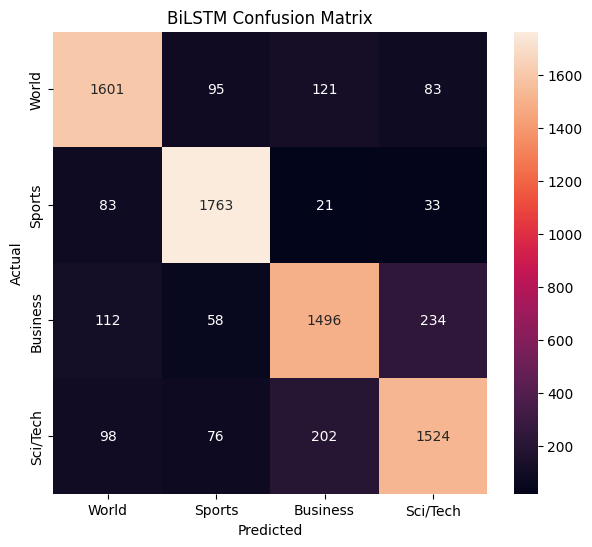

In [35]:
# ==========================================
# CELL 35: BiLSTM CONFUSION MATRIX
# ==========================================

cm_bilstm = confusion_matrix(
    bilstm_true,
    bilstm_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_bilstm,
    annot=True,
    fmt="d",
    xticklabels=label_names.values(),
    yticklabels=label_names.values()
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "BiLSTM Confusion Matrix"
)

plt.show()

In [36]:
# ==========================================
# CELL 36: BERT IMPORTS
# ==========================================

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoModelForSequenceClassification
)

print("Transformers imported!")

Transformers imported!


In [37]:
# ==========================================
# CELL 37: BERT TOKENIZER
# ==========================================

BERT_MODEL_NAME = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(
    BERT_MODEL_NAME
)

print(
    "BERT tokenizer loaded!"
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT tokenizer loaded!


In [38]:
# ==========================================
# CELL 38: BERT TOKENIZATION DEMO
# ==========================================

sample_text = train_df["text"].iloc[0]

tokens = bert_tokenizer.tokenize(
    sample_text
)

token_ids = bert_tokenizer.encode(
    sample_text,
    add_special_tokens=True
)

print("Original text:")
print(sample_text)

print("\nBERT tokens:")
print(tokens[:30])

print("\nToken IDs:")
print(token_ids[:30])

Original text:
Review: Robovacs No Match for Vacuum A new generation of robotic vacuums is ready to do battle with dirt, dust and dog hair with more cleaning power and cunning than their ancestors could muster. Faced with the usual obstacles - furniture, stairs, low-hanging bed skirts and stray socks - they intelligently and acrobatically extricate themselves from most tight spots and largely avoid getting stuck or sucking in what they shouldn't.

BERT tokens:
['review', ':', 'rob', '##ova', '##cs', 'no', 'match', 'for', 'vacuum', 'a', 'new', 'generation', 'of', 'robotic', 'vacuum', '##s', 'is', 'ready', 'to', 'do', 'battle', 'with', 'dirt', ',', 'dust', 'and', 'dog', 'hair', 'with', 'more']

Token IDs:
[101, 3319, 1024, 6487, 7103, 6169, 2053, 2674, 2005, 11641, 1037, 2047, 4245, 1997, 20478, 11641, 2015, 2003, 3201, 2000, 2079, 2645, 2007, 6900, 1010, 6497, 1998, 3899, 2606, 2007]


In [39]:
# ==========================================
# CELL 39: CREATE BERT DATASETS
# ==========================================

from datasets import Dataset

bert_train_df = train_df[
    ["text", "label"]
].copy()

bert_val_df = val_df[
    ["text", "label"]
].copy()

bert_test_df = test_df[
    ["text", "label"]
].copy()

bert_train_dataset = Dataset.from_pandas(
    bert_train_df,
    preserve_index=False
)

bert_val_dataset = Dataset.from_pandas(
    bert_val_df,
    preserve_index=False
)

bert_test_dataset = Dataset.from_pandas(
    bert_test_df,
    preserve_index=False
)

print(bert_train_dataset)
print(bert_val_dataset)
print(bert_test_dataset)

Dataset({
    features: ['text', 'label'],
    num_rows: 16000
})
Dataset({
    features: ['text', 'label'],
    num_rows: 4000
})
Dataset({
    features: ['text', 'label'],
    num_rows: 7600
})


In [40]:
# ==========================================
# CELL 40: BERT TOKENIZATION FUNCTION
# ==========================================

BERT_MAX_LENGTH = 128

def tokenize_bert(batch):

    return bert_tokenizer(
        batch["text"],
        padding="max_length",
        truncation=True,
        max_length=BERT_MAX_LENGTH
    )

In [41]:
# ==========================================
# CELL 41: TOKENIZE BERT DATASETS
# ==========================================

bert_train_tokenized = (
    bert_train_dataset.map(
        tokenize_bert,
        batched=True
    )
)

bert_val_tokenized = (
    bert_val_dataset.map(
        tokenize_bert,
        batched=True
    )
)

bert_test_tokenized = (
    bert_test_dataset.map(
        tokenize_bert,
        batched=True
    )
)

print("BERT tokenization completed!")

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

BERT tokenization completed!


In [42]:
# ==========================================
# CELL 42: PYTORCH FORMAT
# ==========================================

bert_train_tokenized.set_format(
    "torch",
    columns=[
        "input_ids",
        "attention_mask",
        "label"
    ]
)

bert_val_tokenized.set_format(
    "torch",
    columns=[
        "input_ids",
        "attention_mask",
        "label"
    ]
)

bert_test_tokenized.set_format(
    "torch",
    columns=[
        "input_ids",
        "attention_mask",
        "label"
    ]
)

print("BERT datasets converted to PyTorch format!")

BERT datasets converted to PyTorch format!


In [43]:
# ==========================================
# CELL 43: BERT DATALOADERS
# ==========================================

BERT_TRAIN_BATCH_SIZE = 16
BERT_EVAL_BATCH_SIZE = 32

bert_train_loader = DataLoader(
    bert_train_tokenized,
    batch_size=BERT_TRAIN_BATCH_SIZE,
    shuffle=True
)

bert_val_loader = DataLoader(
    bert_val_tokenized,
    batch_size=BERT_EVAL_BATCH_SIZE,
    shuffle=False
)

bert_test_loader = DataLoader(
    bert_test_tokenized,
    batch_size=BERT_EVAL_BATCH_SIZE,
    shuffle=False
)

print("BERT DataLoaders ready!")


BERT DataLoaders ready!


In [44]:
# ==========================================
# CELL 44: LOAD PRETRAINED BERT
# ==========================================

bert_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        BERT_MODEL_NAME,
        num_labels=4
    )
)

bert_model = bert_model.to(device)

print(
    "BERT model loaded!"
)

print(
    "Device:",
    device
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded!
Device: cuda


In [45]:
# ==========================================
# CELL 45: BERT OPTIMIZER
# ==========================================

bert_optimizer = optim.AdamW(
    bert_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

BERT_EPOCHS = 2

print("BERT optimizer ready!")

BERT optimizer ready!


In [46]:
# ==========================================
# CELL 46: BERT TRAINING FUNCTION
# ==========================================

def train_bert_epoch(
    model,
    loader,
    optimizer
):

    model.train()

    total_loss = 0

    all_predictions = []
    all_labels = []

    for batch in loader:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        labels = batch[
            "label"
        ].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        logits = outputs.logits

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = logits.argmax(
            dim=1
        )

        all_predictions.extend(
            predictions.detach()
            .cpu()
            .numpy()
        )

        all_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    avg_loss = (
        total_loss / len(loader)
    )

    return avg_loss, accuracy, f1

In [47]:
# ==========================================
# CELL 47: BERT EVALUATION
# ==========================================

def evaluate_bert(
    model,
    loader
):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch[
                "input_ids"
            ].to(device)

            attention_mask = batch[
                "attention_mask"
            ].to(device)

            labels = batch[
                "label"
            ].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            predictions = (
                outputs.logits
                .argmax(dim=1)
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return (
        accuracy,
        f1,
        all_labels,
        all_predictions
    )

In [48]:
# ==========================================
# CELL 48: FINE-TUNE BERT
# ==========================================

bert_start_time = time.time()

bert_history = []

for epoch in range(BERT_EPOCHS):

    loss, train_acc, train_f1 = (
        train_bert_epoch(
            bert_model,
            bert_train_loader,
            bert_optimizer
        )
    )

    val_acc, val_f1, _, _ = (
        evaluate_bert(
            bert_model,
            bert_val_loader
        )
    )

    bert_history.append({
        "epoch": epoch + 1,
        "loss": loss,
        "train_accuracy": train_acc,
        "train_f1": train_f1,
        "val_accuracy": val_acc,
        "val_f1": val_f1
    })

    print(
        f"Epoch {epoch+1}/{BERT_EPOCHS} | "
        f"Loss: {loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

bert_training_time = (
    time.time()
    - bert_start_time
)

print(
    "\nBERT training time:",
    round(
        bert_training_time,
        2
    ),
    "seconds"
)

Epoch 1/2 | Loss: 0.3352 | Train Acc: 0.8888 | Val Acc: 0.9230 | Val F1: 0.9227
Epoch 2/2 | Loss: 0.1654 | Train Acc: 0.9457 | Val Acc: 0.9303 | Val F1: 0.9301

BERT training time: 800.37 seconds


In [49]:
# ==========================================
# CELL 49: BERT TEST RESULTS
# ==========================================

(
    bert_accuracy,
    bert_f1,
    bert_true,
    bert_pred
) = evaluate_bert(
    bert_model,
    bert_test_loader
)

print(
    "BERT Test Accuracy:",
    round(bert_accuracy, 4)
)

print(
    "BERT Test Macro F1:",
    round(bert_f1, 4)
)

print(
    "BERT Training Time:",
    round(
        bert_training_time,
        2
    ),
    "seconds"
)

BERT Test Accuracy: 0.9293
BERT Test Macro F1: 0.9291
BERT Training Time: 800.37 seconds


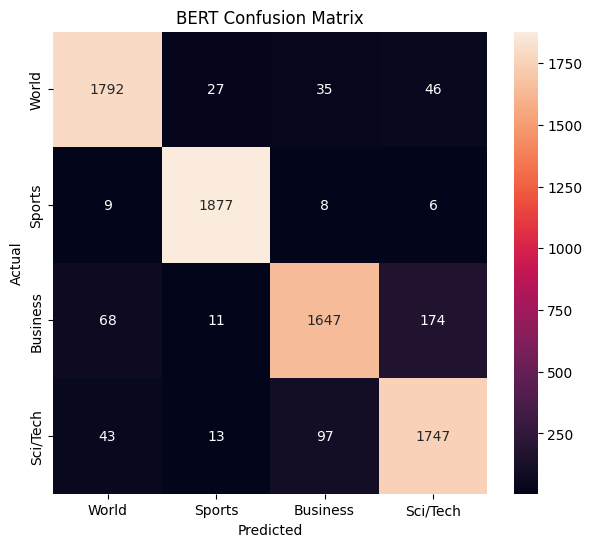

In [50]:
# ==========================================
# CELL 50: BERT CONFUSION MATRIX
# ==========================================

cm_bert = confusion_matrix(
    bert_true,
    bert_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_bert,
    annot=True,
    fmt="d",
    xticklabels=label_names.values(),
    yticklabels=label_names.values()
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "BERT Confusion Matrix"
)

plt.show()

In [51]:
# ==========================================
# CELL 51: DATA EFFICIENCY SUBSETS
# ==========================================

def create_balanced_subset(
    dataframe,
    total_samples
):

    samples_per_class = (
        total_samples // 4
    )

    subset = (
        dataframe
        .groupby(
            "label",
            group_keys=False
        )
        .sample(
            n=samples_per_class,
            random_state=SEED
        )
        .sample(
            frac=1,
            random_state=SEED
        )
        .reset_index(drop=True)
    )

    return subset


train_2k = create_balanced_subset(
    train_df,
    2000
)

train_5k = create_balanced_subset(
    train_df,
    5000
)

train_10k = create_balanced_subset(
    train_df,
    10000
)

train_15k = create_balanced_subset(
    train_df,
    15000
)

train_16k = train_df.copy()

print("2K :", len(train_2k))
print("5K :", len(train_5k))
print("10K:", len(train_10k))
print("15K:", len(train_15k))
print("16K:", len(train_16k))

2K : 2000
5K : 5000
10K: 10000
15K: 15000
16K: 16000


In [52]:
# ==========================================
# CELL 52: CREATE BERT LOADER
# ==========================================

def create_bert_loader(
    dataframe,
    batch_size=16
):

    temp_dataset = Dataset.from_pandas(
        dataframe[
            ["text", "label"]
        ].reset_index(drop=True),
        preserve_index=False
    )

    temp_dataset = temp_dataset.map(
        tokenize_bert,
        batched=True
    )

    temp_dataset.set_format(
        "torch",
        columns=[
            "input_ids",
            "attention_mask",
            "label"
        ]
    )

    loader = DataLoader(
        temp_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    return loader

In [53]:
# ==========================================
# CELL 53: DATA EFFICIENCY FUNCTION
# ==========================================

def run_bert_experiment(
    train_dataframe,
    train_size
):

    print("\n" + "=" * 60)

    print(
        f"Training BERT with "
        f"{train_size} samples"
    )

    print("=" * 60)

    loader = create_bert_loader(
        train_dataframe,
        batch_size=16
    )

    model = (
        AutoModelForSequenceClassification
        .from_pretrained(
            BERT_MODEL_NAME,
            num_labels=4
        )
    )

    model = model.to(device)

    optimizer = optim.AdamW(
        model.parameters(),
        lr=2e-5,
        weight_decay=0.01
    )

    start_time = time.time()

    for epoch in range(2):

        loss, acc, f1 = (
            train_bert_epoch(
                model,
                loader,
                optimizer
            )
        )

        print(
            f"Epoch {epoch+1}/2 | "
            f"Loss: {loss:.4f} | "
            f"Accuracy: {acc:.4f} | "
            f"F1: {f1:.4f}"
        )

    training_time = (
        time.time() - start_time
    )

    test_accuracy, test_f1, _, _ = (
        evaluate_bert(
            model,
            bert_test_loader
        )
    )

    print(
        "\nTest Accuracy:",
        round(test_accuracy, 4)
    )

    print(
        "Test Macro F1:",
        round(test_f1, 4)
    )

    print(
        "Training Time:",
        round(training_time, 2),
        "seconds"
    )

    return (
        test_accuracy,
        test_f1,
        training_time
    )

In [54]:
# ==========================================
# CELL 54: BERT - 2K
# ==========================================

acc_2k, f1_2k, time_2k = (
    run_bert_experiment(
        train_2k,
        2000
    )
)


Training BERT with 2000 samples


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/2 | Loss: 0.6593 | Accuracy: 0.7925 | F1: 0.7912
Epoch 2/2 | Loss: 0.2645 | Accuracy: 0.9220 | F1: 0.9219

Test Accuracy: 0.9018
Test Macro F1: 0.9021
Training Time: 94.01 seconds


In [55]:
# ==========================================
# CELL 55: BERT - 5K
# ==========================================

acc_5k, f1_5k, time_5k = (
    run_bert_experiment(
        train_5k,
        5000
    )
)


Training BERT with 5000 samples


Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/2 | Loss: 0.4520 | Accuracy: 0.8486 | F1: 0.8492
Epoch 2/2 | Loss: 0.2067 | Accuracy: 0.9334 | F1: 0.9334

Test Accuracy: 0.9039
Test Macro F1: 0.9033
Training Time: 231.65 seconds


In [56]:
# ==========================================
# CELL 56: BERT - 10K
# ==========================================

acc_10k, f1_10k, time_10k = (
    run_bert_experiment(
        train_10k,
        10000
    )
)


Training BERT with 10000 samples


Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/2 | Loss: 0.3783 | Accuracy: 0.8752 | F1: 0.8751
Epoch 2/2 | Loss: 0.1800 | Accuracy: 0.9407 | F1: 0.9407

Test Accuracy: 0.9186
Test Macro F1: 0.9181
Training Time: 462.91 seconds


In [57]:
# ==========================================
# CELL 57: BERT - 15K
# ==========================================

acc_15k, f1_15k, time_15k = (
    run_bert_experiment(
        train_15k,
        15000
    )
)


Training BERT with 15000 samples


Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/2 | Loss: 0.3272 | Accuracy: 0.8914 | F1: 0.8911
Epoch 2/2 | Loss: 0.1682 | Accuracy: 0.9434 | F1: 0.9434

Test Accuracy: 0.9221
Test Macro F1: 0.9222
Training Time: 691.81 seconds


In [58]:
# ==========================================
# CELL 58: FULL 16K RESULT
# ==========================================

acc_16k = bert_accuracy
f1_16k = bert_f1
time_16k = bert_training_time

print(
    "16K Accuracy:",
    round(acc_16k, 4)
)

print(
    "16K F1:",
    round(f1_16k, 4)
)

print(
    "16K Training Time:",
    round(time_16k, 2),
    "seconds"
)

16K Accuracy: 0.9293
16K F1: 0.9291
16K Training Time: 800.37 seconds


In [59]:
# ==========================================
# CELL 59: DATA EFFICIENCY TABLE
# ==========================================

data_efficiency_results = pd.DataFrame({

    "Training Size": [
        2000,
        5000,
        10000,
        15000,
        16000
    ],

    "Accuracy": [
        acc_2k,
        acc_5k,
        acc_10k,
        acc_15k,
        acc_16k
    ],

    "Macro F1": [
        f1_2k,
        f1_5k,
        f1_10k,
        f1_15k,
        f1_16k
    ],

    "Training Time (sec)": [
        time_2k,
        time_5k,
        time_10k,
        time_15k,
        time_16k
    ]
})

data_efficiency_results

,Training Size,Accuracy,Macro F1,Training Time (sec)
0,2000,0.901842,0.902125,94.008786
1,5000,0.903947,0.903308,231.649863
2,10000,0.918553,0.918141,462.906846
3,15000,0.922105,0.922196,691.810653
4,16000,0.929342,0.929102,800.365137


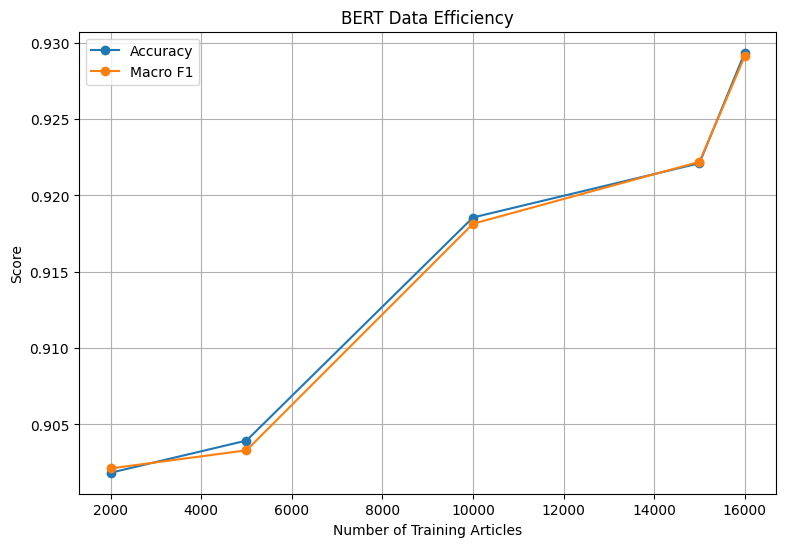

In [60]:
# ==========================================
# CELL 60: DATA EFFICIENCY GRAPH
# ==========================================

plt.figure(figsize=(9, 6))

plt.plot(
    data_efficiency_results[
        "Training Size"
    ],
    data_efficiency_results[
        "Accuracy"
    ],
    marker="o",
    label="Accuracy"
)

plt.plot(
    data_efficiency_results[
        "Training Size"
    ],
    data_efficiency_results[
        "Macro F1"
    ],
    marker="o",
    label="Macro F1"
)

plt.xlabel(
    "Number of Training Articles"
)

plt.ylabel("Score")

plt.title(
    "BERT Data Efficiency"
)

plt.legend()

plt.grid(True)

plt.show()

In [61]:
# ==========================================
# CELL 61: FINAL MODEL COMPARISON
# ==========================================

comparison_df = pd.DataFrame({

    "Model": [
        "BiLSTM",
        "BERT"
    ],

    "Accuracy": [
        bilstm_accuracy,
        bert_accuracy
    ],

    "Macro F1": [
        bilstm_f1,
        bert_f1
    ],

    "Training Time (sec)": [
        bilstm_training_time,
        bert_training_time
    ]
})

comparison_df

,Model,Accuracy,Macro F1,Training Time (sec)
0,BiLSTM,0.840000,0.839389,15.439678
1,BERT,0.929342,0.929102,800.365137


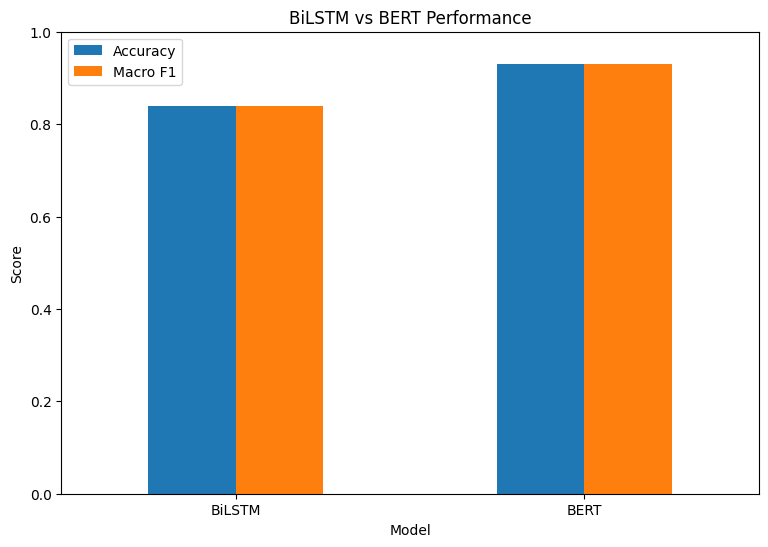

In [62]:
# ==========================================
# CELL 62: MODEL COMPARISON GRAPH
# ==========================================

comparison_scores = comparison_df.set_index(
    "Model"
)[
    [
        "Accuracy",
        "Macro F1"
    ]
]

comparison_scores.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title(
    "BiLSTM vs BERT Performance"
)

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(
    rotation=0
)

plt.show()

In [67]:
# Enable attention outputs for visualization

bert_model.set_attn_implementation("eager")
bert_model.config.output_attentions = True

print("Attention output enabled successfully!")

Attention output enabled successfully!


In [68]:
# ==========================================
# CELL 64: SELECT SAMPLE ARTICLE
# ==========================================

attention_sample_text = (
    test_df["text"].iloc[0]
)

attention_sample_label = (
    test_df["label"].iloc[0]
)

print("Article:")
print(
    attention_sample_text
)

print("\nActual category:")

print(
    label_names[
        attention_sample_label
    ]
)

Article:
Fears for T N pension after talks Unions representing workers at Turner   Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.

Actual category:
Business


In [69]:
# ==========================================
# CELL 65: TOKENIZE SAMPLE
# ==========================================

attention_inputs = bert_tokenizer(
    attention_sample_text,
    return_tensors="pt",
    truncation=True,
    max_length=64
)

attention_inputs = {
    key: value.to(device)
    for key, value
    in attention_inputs.items()
}

attention_tokens = (
    bert_tokenizer.convert_ids_to_tokens(
        attention_inputs[
            "input_ids"
        ][0]
    )
)

print(
    "Tokens:"
)

print(
    attention_tokens
)

Tokens:
['[CLS]', 'fears', 'for', 't', 'n', 'pension', 'after', 'talks', 'unions', 'representing', 'workers', 'at', 'turner', 'new', '##all', 'say', 'they', 'are', "'", 'disappointed', "'", 'after', 'talks', 'with', 'stricken', 'parent', 'firm', 'federal', 'mo', '##gul', '.', '[SEP]']


In [70]:
# ==========================================
# CELL 66: EXTRACT ATTENTION WEIGHTS
# ==========================================

with torch.no_grad():

    attention_output = bert_model(
        **attention_inputs,
        output_attentions=True
    )

attentions = (
    attention_output.attentions
)

print(
    "Number of BERT layers:",
    len(attentions)
)

print(
    "Attention shape:",
    attentions[-1].shape
)

Number of BERT layers: 12
Attention shape: torch.Size([1, 12, 32, 32])


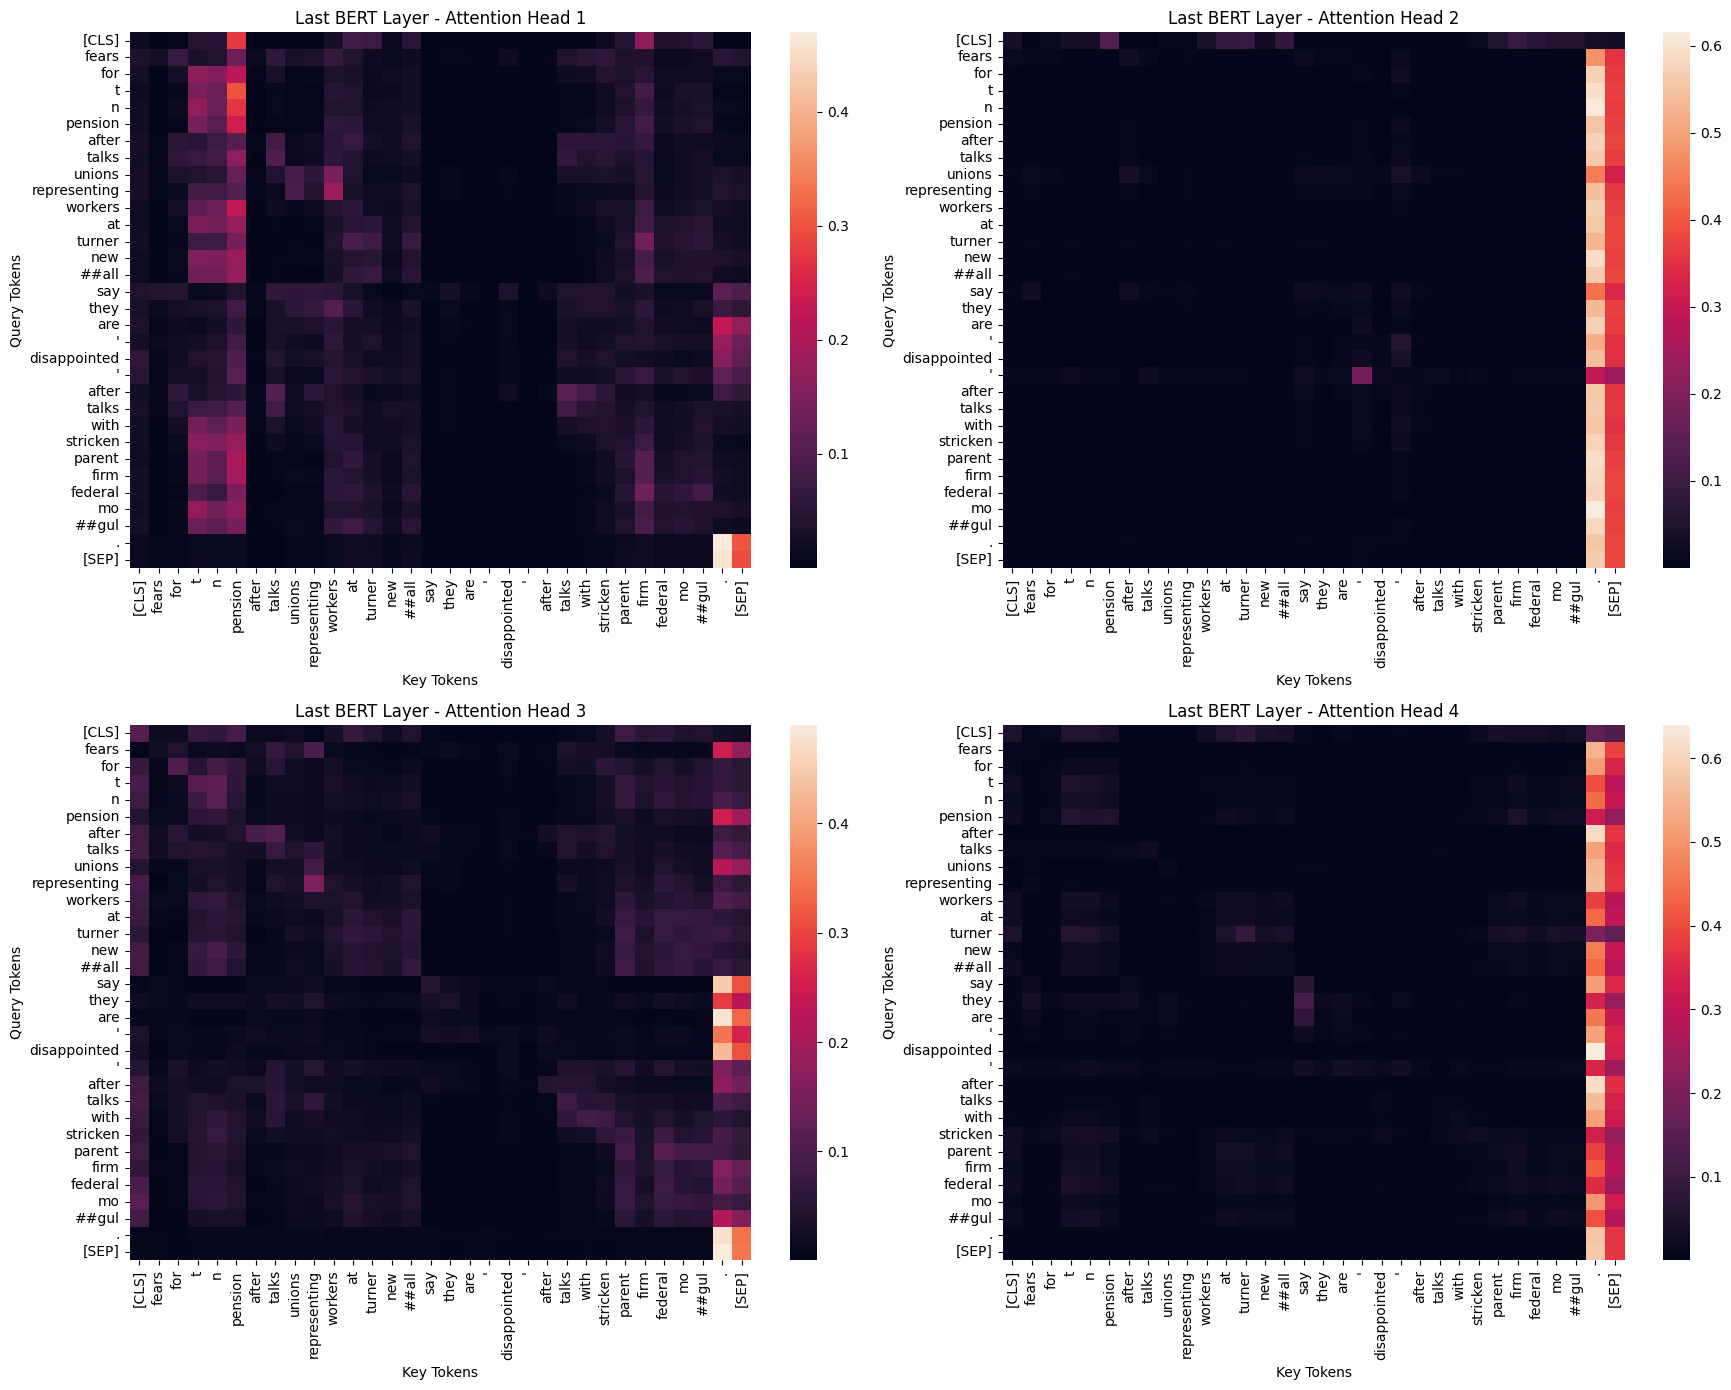

In [71]:
# ==========================================
# CELL 67: MULTI-HEAD ATTENTION
# ==========================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(18, 14)
)

last_layer_attention = (
    attentions[-1][0]
    .detach()
    .cpu()
    .numpy()
)

for head_index, ax in enumerate(
    axes.flat
):

    sns.heatmap(
        last_layer_attention[
            head_index
        ],
        xticklabels=attention_tokens,
        yticklabels=attention_tokens,
        ax=ax
    )

    ax.set_title(
        f"Last BERT Layer - "
        f"Attention Head {head_index + 1}"
    )

    ax.set_xlabel(
        "Key Tokens"
    )

    ax.set_ylabel(
        "Query Tokens"
    )

    ax.tick_params(
        axis="x",
        rotation=90
    )

    ax.tick_params(
        axis="y",
        rotation=0
    )

plt.tight_layout()

plt.show()

In [72]:
# ==========================================
# CELL 68: FINAL SUMMARY
# ==========================================

print("=" * 70)

print(
    "NEWS ARTICLE TOPIC CLASSIFICATION"
)

print("=" * 70)

print("\nDATASET")
print(
    "Total selected articles: 20,000"
)

print(
    "Training articles: 16,000"
)

print(
    "Validation articles: 4,000"
)

print(
    "Official test articles: 7,600"
)

print("\n" + "=" * 70)

print("BiLSTM RESULTS")

print(
    "Accuracy:",
    round(bilstm_accuracy, 4)
)

print(
    "Macro F1:",
    round(bilstm_f1, 4)
)

print(
    "Training Time:",
    round(
        bilstm_training_time,
        2
    ),
    "seconds"
)

print("\n" + "=" * 70)

print("BERT RESULTS")

print(
    "Accuracy:",
    round(bert_accuracy, 4)
)

print(
    "Macro F1:",
    round(bert_f1, 4)
)

print(
    "Training Time:",
    round(
        bert_training_time,
        2
    ),
    "seconds"
)

print("\n" + "=" * 70)

print("DATA EFFICIENCY")

print(
    data_efficiency_results
)

print("=" * 70)

NEWS ARTICLE TOPIC CLASSIFICATION

DATASET
Total selected articles: 20,000
Training articles: 16,000
Validation articles: 4,000
Official test articles: 7,600

BiLSTM RESULTS
Accuracy: 0.84
Macro F1: 0.8394
Training Time: 15.44 seconds

BERT RESULTS
Accuracy: 0.9293
Macro F1: 0.9291
Training Time: 800.37 seconds

DATA EFFICIENCY
   Training Size  Accuracy  Macro F1  Training Time (sec)
0           2000  0.901842  0.902125            94.008786
1           5000  0.903947  0.903308           231.649863
2          10000  0.918553  0.918141           462.906846
3          15000  0.922105  0.922196           691.810653
4          16000  0.929342  0.929102           800.365137


In [73]:
# ==========================================
# CELL 69: SAVE RESULTS
# ==========================================

comparison_df.to_csv(
    "bilstm_vs_bert_results.csv",
    index=False
)

data_efficiency_results.to_csv(
    "bert_data_efficiency_results.csv",
    index=False
)

print(
    "Results saved successfully!"
)

Results saved successfully!
